# SOXL历史相似区间与训练覆盖审计

A是完成后的44日形态描述，B只按8/31收盘可知状态检索。固定40/44/60及20/60敏感性、P5描述性距离参照、完整支撑区间purge与重叠去簇均在提取数据前注册。2026目标与被反复查看的外层不是新的clean OOS。本卡不重训、不改active模型或模拟账户。


In [1]:
from pathlib import Path
import os, sys, json
os.environ.setdefault('MLFLOW_ALLOW_FILE_STORE', 'true')
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')
root = Path.cwd().resolve()
while not (root/'AGENTS.md').exists():
    if root == root.parent: raise RuntimeError('workspace root not found')
    root = root.parent
sys.path.insert(0, str(root))
import qlib
from qlib.data import D
from qlib.workflow import R
from IPython.display import display, Image
from src.analysis.soxl_historical_analog import run_historical_analog_card
card = root/'research/soxl_historical_analog_20260929'
# D API extraction is first-run only; retained Recorder inputs are hash checked on rerun.
# All provider changes and training-coverage reads occur before R.start.
summary = run_historical_analog_card(root=root, recorder_uri=Path('/Users/rziiiii/dev/workspace/research/soxl_historical_analog_20260929/qlib_recorder'))


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


[36879:MainThread](2026-09-29 14:43:42,361) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[36879:MainThread](2026-09-29 14:43:42,364) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[36879:MainThread](2026-09-29 14:43:42,364) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/Users/rziiiii/dev/.worktrees/soxl-analog-20260929/data/qlib/soxl')}


[36879:MainThread](2026-09-29 14:43:42,399) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[36879:MainThread](2026-09-29 14:43:42,400) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[36879:MainThread](2026-09-29 14:43:42,400) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': PosixPath('/Users/rziiiii/dev/.worktrees/soxl-analog-20260929/data/qlib/soxl')}


[36879:MainThread](2026-09-29 14:43:42,402) INFO - qlib.workflow - [exp.py:258] - Experiment 603588725174536412 starts running ...


[36879:MainThread](2026-09-29 14:43:42,488) INFO - qlib.workflow - [recorder.py:345] - Recorder 32085144fa2c4989999530d8ed7c9c8a starts running under Experiment 603588725174536412 ...


[36879:MainThread](2026-09-29 14:43:43,442) INFO - qlib.timer - [log.py:127] - Time cost: 0.000s | waiting `async_log` Done


In [2]:
import pandas as pd
display(pd.read_csv(card/'retrieval_counts.csv'))
events = pd.read_csv(card/'analog_events.csv')
display(events[events.window_spec.isin(['A44','B20_60'])])
summary['training_coverage']


,window_spec,cohort,raw_candidate_count,boundary_purged_count,below_p5_reference_count,nonoverlap_representative_count,nonoverlap_below_p5_count,p5_distance_reference,reference_pair_count,nearest_distance,nearest_reference_percentile
0,A44,training_2011_2022,2977,43,0,56,0,0.440917,10731,0.537384,10.642065
1,A44,untrained_2023_2025,709,43,0,13,0,0.440917,10731,0.454775,5.749697
2,A40,training_2011_2022,2981,39,0,62,0,0.447722,11026,0.532246,9.559224
3,A40,untrained_2023_2025,713,39,6,15,1,0.447722,11026,0.361410,1.541810
4,A60,training_2011_2022,2961,59,0,37,0,0.457006,10731,0.794877,28.310502
5,A60,untrained_2023_2025,693,59,0,10,0,0.457006,10731,0.683466,19.727891
6,B20_60,training_2011_2022,2940,80,0,28,0,0.565103,10153,1.007522,30.641190
7,B20_60,untrained_2023_2025,672,80,0,7,0,0.565103,10153,0.748045,13.936767
8,B20,training_2011_2022,2980,40,0,56,0,0.485337,10731,0.522188,6.131768
9,B20,untrained_2023_2025,712,40,9,15,3,0.485337,10731,0.269963,0.288883


,event_id,retrieval_kind,window_spec,anchor_date,feature_start,feature_end,support_start,support_end,outcome_start,outcome_end,...,soxx_forward_18_return_pct,soxx_forward_18_max_drawdown_pct,soxl_forward_18_return_pct,soxl_forward_18_max_drawdown_pct,forward_20_complete,forward_20_observed_sessions,soxx_forward_20_return_pct,soxx_forward_20_max_drawdown_pct,soxl_forward_20_return_pct,soxl_forward_20_max_drawdown_pct
0,A44_20210427,A_retrospective,A44,2021-04-27,2021-02-24,2021-04-27,2021-02-24,2021-04-27,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A44_20181213,A_retrospective,A44,2018-12-13,2018-10-11,2018-12-13,2018-10-11,2018-12-13,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A44_20190911,A_retrospective,A44,2019-09-11,2019-07-11,2019-09-11,2019-07-11,2019-09-11,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A44_20251208,A_retrospective,A44,2025-12-08,2025-10-07,2025-12-08,2025-10-07,2025-12-08,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A44_20241015,A_retrospective,A44,2024-10-15,2024-08-14,2024-10-15,2024-08-14,2024-10-15,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,A44_20240731,A_retrospective,A44,2024-07-31,2024-05-29,2024-07-31,2024-05-29,2024-07-31,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
18,B20_60_20220407,B_asof_state,B20_60,2022-04-07,2022-01-11,2022-04-07,2022-01-11,2022-05-06,2022-04-08,2022-05-06,...,-1.346350,-9.758711,-8.161259,-28.056371,True,20.0,-6.961411,-9.758711,-23.467714,-28.056371
19,B20_60_20181214,B_asof_state,B20_60,2018-12-14,2018-09-19,2018-12-14,2018-09-19,2019-01-15,2018-12-17,2019-01-15,...,2.922261,-9.459883,4.281449,-25.829273,True,20.0,1.542318,-9.459883,0.000000,-25.829273
20,B20_60_20221031,B_asof_state,B20_60,2022-10-31,2022-08-05,2022-10-31,2022-08-05,2022-11-29,2022-11-01,2022-11-29,...,15.446579,-4.767847,44.170403,-14.275414,True,20.0,12.126314,-4.884768,31.502235,-15.428984
21,B20_60_20240912,B_asof_state,B20_60,2024-09-12,2024-06-17,2024-09-12,2024-06-17,2024-10-10,2024-09-13,2024-10-10,...,6.293964,-5.202383,17.761707,-14.678437,True,20.0,6.650221,-5.202383,18.924881,-14.678437


{'status': 'audited',
 'base_recorder_id': 'f696f656b3d44e868588e09a5d97c905',
 'action_recorder_id': 'b472a458fc9042b4905094fddeaebd33',
 'training_information_cutoff': '2022-12-30',
 'label_maturity': {'training_information_cutoff': '2022-12-30',
  'primary_label_timing': 'five T+1 open to T+2 open returns; final realization is fifth exit_date',
  'excluded_cross_boundary_signal_rows': 6,
  'last_mature_training_signal': '2022-12-21',
  'last_training_label_realization': '2022-12-30'},
 'primary_actual_fit_rows': 3014,
 'auxiliary_actual_fit_rows': 20741,
 'primary_tail_positive_rows': 204,
 'primary_tail_operational_overlap_clusters': 67,
 'auxiliary_unique_dates': 776,
 'auxiliary_positive_crash_rows': 3834,
 'auxiliary_operational_overlap_clusters': 29,
 'sampling': {'method': 'uniform row sampling with replacement; normalized training_weight multiplies per-row BCE',
  'epochs': 300,
  'batch_size': 2048,
  'expected_total_auxiliary_draws': 614400,
  'loss_coefficient': 0.05},
 'a

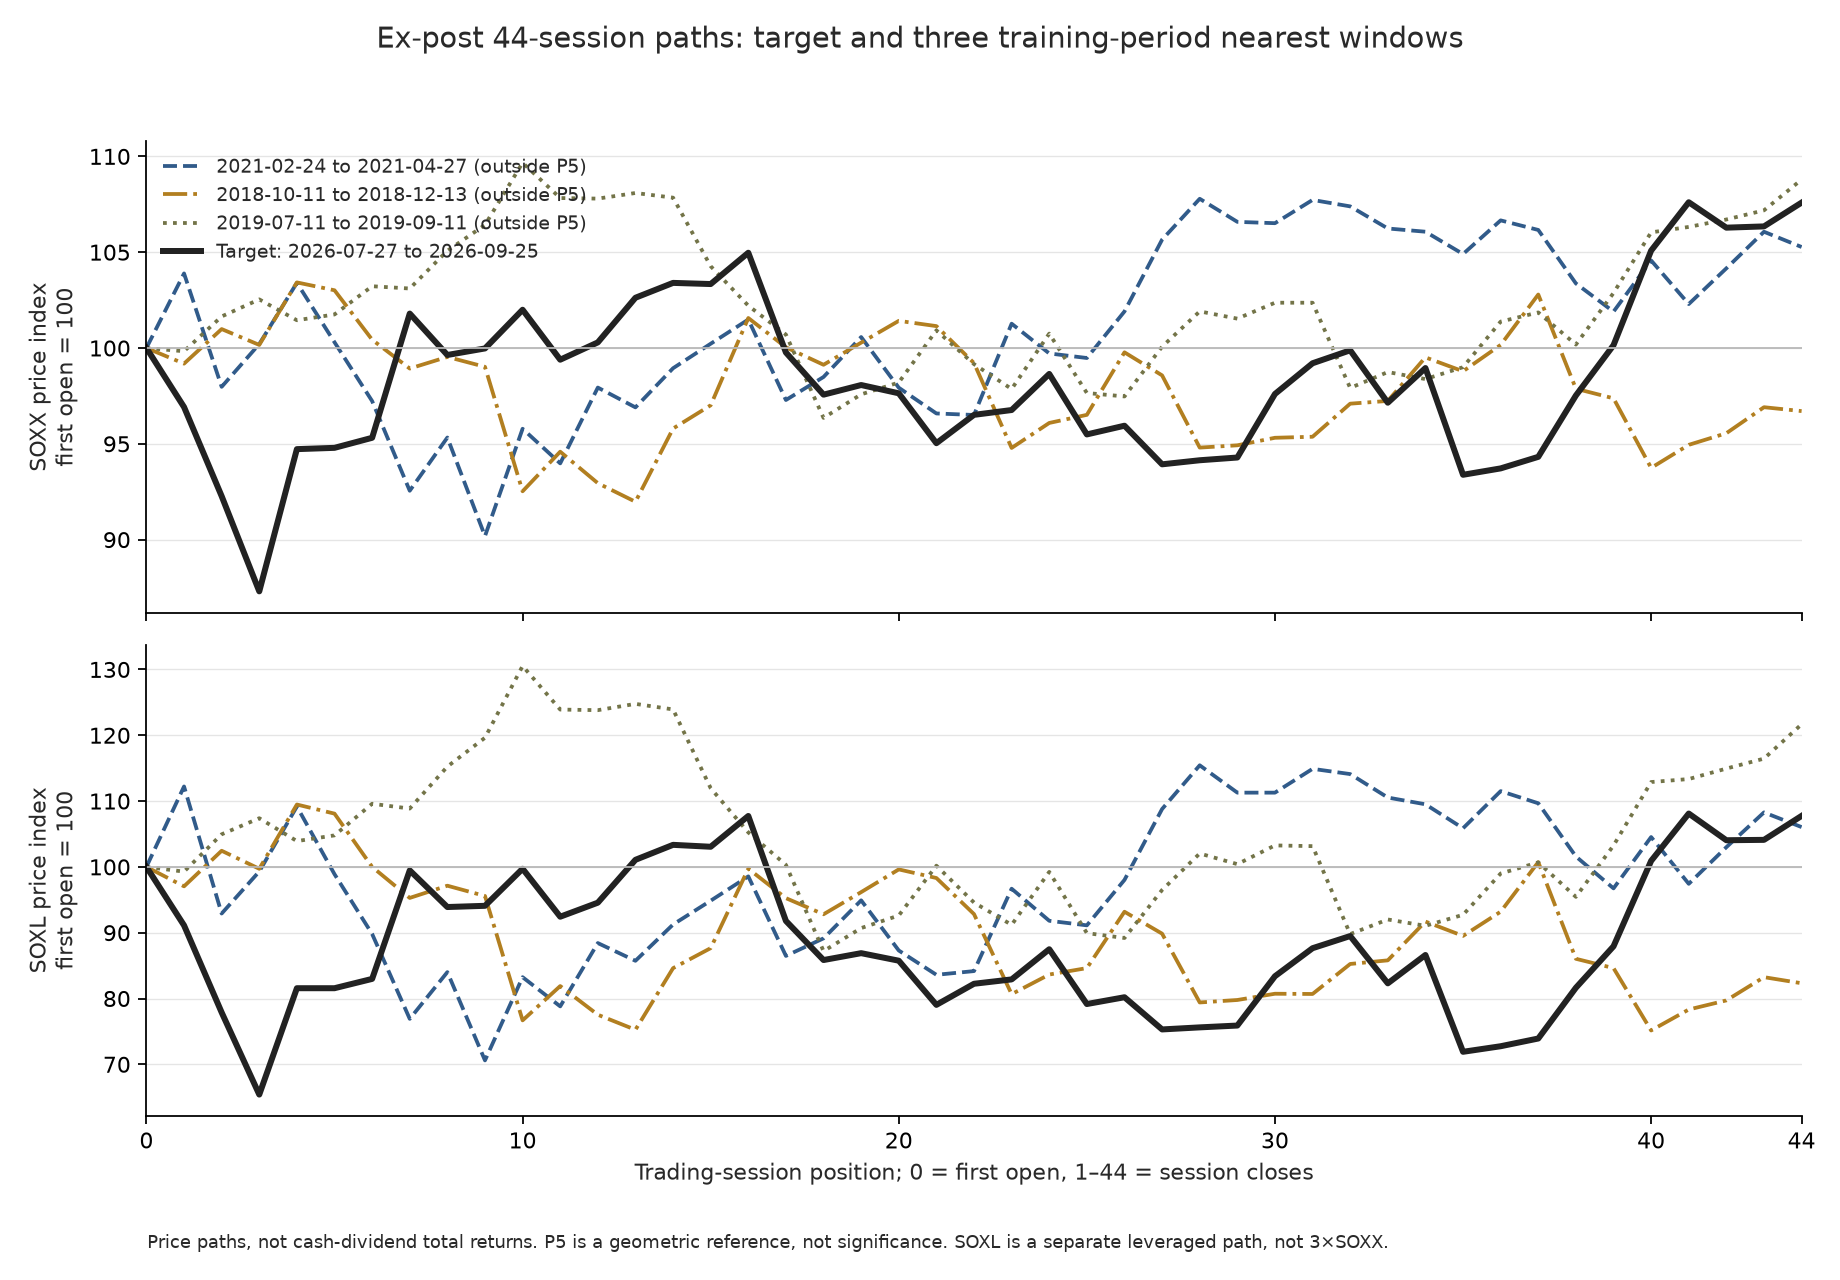

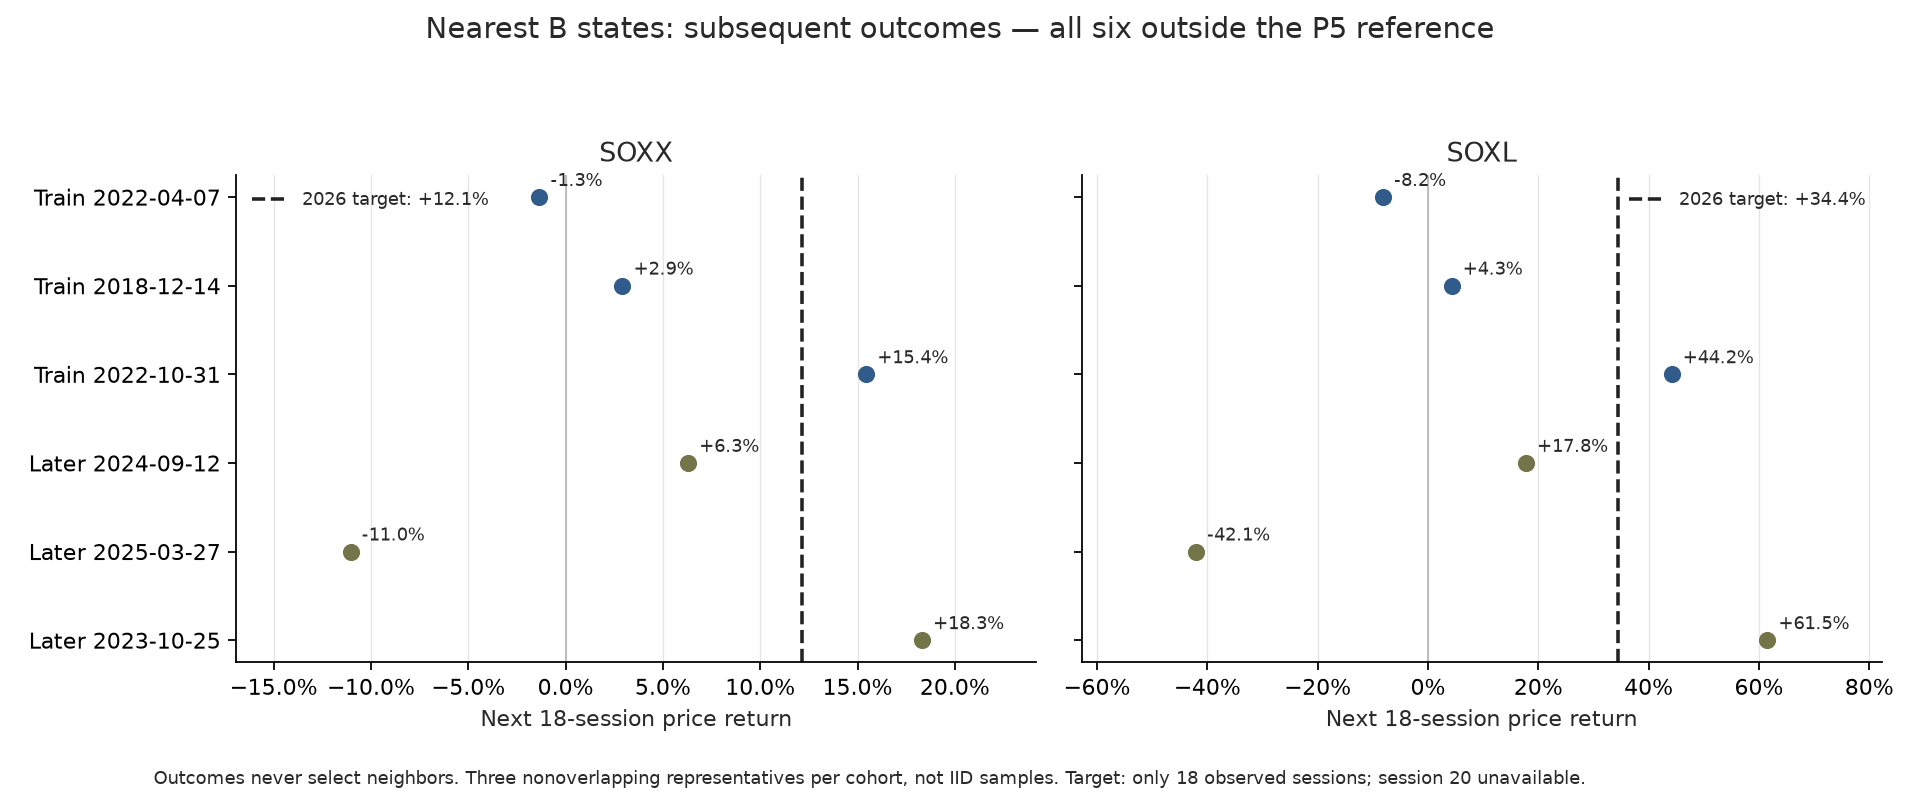

In [3]:
for figure in summary['figures']:
    display(Image(filename=str(Path(summary['recorder_local_dir'])/figure)))


## 中文结论

相似阈值只描述几何距离，不能解释为预测成功率；A不可直接选B训练样本。完整20日目标尚未完成，保留已观察18日，不外推。

[后续人工研究计划](training_data_plan.md)：仅为提案，尚未训练或验证。


In [4]:
print((card/'conclusion.md').read_text())


# 中文结论

本卡区分完整路径的事后形态诊断A与8/31收盘已知状态检索B；不训练模型、不修改模拟盘。所有行情锁定9/25快照，通过QLib D提取并保留完整输入。

- A44/training_2011_2022：检索2977个窗口，边界purge 43个；P5内原始窗口0个、非重叠代表0个。最近窗口2021-02-24–2021-04-27，距离0.537、历史距离分布分位10.64%。
- A44/untrained_2023_2025：检索709个窗口，边界purge 43个；P5内原始窗口0个、非重叠代表0个。最近窗口2025-10-07–2025-12-08，距离0.455、历史距离分布分位5.75%。
- B20_60/training_2011_2022：检索2940个窗口，边界purge 80个；P5内原始窗口0个、非重叠代表0个。最近窗口2022-01-11–2022-04-07，距离1.008、历史距离分布分位30.64%。
- B20_60/untrained_2023_2025：检索672个窗口，边界purge 80个；P5内原始窗口0个、非重叠代表0个。最近窗口2024-06-17–2024-09-12，距离0.748、历史距离分布分位13.94%。

训练覆盖：实际主训练3014行，204个tail阳性行合并为67个操作性重叠簇；辅助训练20741行、776个日期，crash阳性只有29个跨资产重叠簇。它们不是IID样本数。
辅助日期名义权重本来接近均匀（逆集中度774.36/776）；crash阳性名义权重的前5簇占67.30%，该分母仅为crash阳性权重，不能解释成总loss或gradient份额。因此不把一般日期均衡当主要修复。
目标末日55维特征有0个超出训练P1–P99、无缺失；44日窗口中163/2420个特征单元越界。单变量范围内不证明联合状态或组合控制器路径已经覆盖。HOLD训练仍基于baseline状态，验证使用自身状态，risk_clock未列入22个动作特征。
优先有界实验：①补自身策略状态/成熟标签与完整episode留出；②在保持总体任务权重下比较一个辅助crash事件集中度上限；③如扩展2022训练截止，必须严格滚动验证并另留新的前向数据。以上仅建议，本卡没有训练候选，也不据2026已经观察的反弹调权重